# Baseline performance: ANN vs SNN

This notebook shows how an ANN and an SNN behave when trained on a sequence of tasks with **no continual-learning mechanism at all**. Each task is trained in turn and nothing protects what was learned before. This is the reference point that EWC, replay and MSCN are measured against (see `ewc.ipynb`).

### Benchmark: Split CIFAR-10
CIFAR-10 is split into 5 tasks of 2 classes, always trained in this order:

| Task | Classes |
|---|---|
| T1 | airplane, automobile |
| T2 | bird, cat |
| T3 | deer, dog |
| T4 | frog, horse |
| T5 | ship, truck |

### Two scenarios
- **Task-incremental:** the model is told which task an image comes from and only chooses between that task's 2 classes. It has a shared body and a separate 2-class output head for each task. Chance = 50%.
- **Class-incremental:** the model is not told the task and must choose among all 10 classes with a single output layer. This is much harder. Chance = 10%.

### Models
- **ANN:** fully connected network, 3072 → 512 → 256 → output, ReLU activations.
- **SNN:** the same layers, with ReLU replaced by leaky integrate-and-fire (LIF) spiking neurons (SpikingJelly). The image is fed in unchanged at every time step (direct encoding), and the output is averaged over **T** time steps. Training uses backpropagation with a sigmoid surrogate gradient.

### Training settings
Adam, learning rate 1e-3, batch size 128, random-crop and horizontal-flip augmentation, 5 seeds (42, 123, 456, 789, 1011).

### Conditions
| Condition | Epochs per task | SNN time steps T |
|---|---|---|
| 1 | 1 | 2 |
| 2 | 2 | 4 |
| 3 | 5 | 7 |

Epochs and T change together, so a difference between conditions can't be pinned on either one alone.

### Metrics
- **Final average accuracy:** mean accuracy over all 5 tasks after the last task is trained.
- **Forgetting:** for each of tasks 1–4, the accuracy right after it was trained minus its accuracy at the end, averaged over those tasks.

Error bars and shaded bands are ±1 standard deviation across seeds. Every figure is also saved to `figures/`.

## Setup
Imports, plot style and helper functions that read the result files and compute the metrics above.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

RESULTS = Path.cwd().parent / "raw_important_results"   # notebook lives in "visualised_results/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9a998f", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
MODEL_COLORS = {"ann": "#2a78d6", "snn": "#eb6834"}
MODEL_NAMES = {"ann": "ANN", "snn": "SNN"}
CHANCE = {"task": 0.5, "class": 0.1}
TASK_NAMES = ["T1 plane/car", "T2 bird/cat", "T3 deer/dog", "T4 frog/horse", "T5 ship/truck"]


def load(rel_path):
    """List of conditions; each has epochs, snn_time_steps and per-model seed runs."""
    with open(RESULTS / rel_path) as f:
        return json.load(f)["conditions"]


def cond_label(c):
    return f"{c['epochs']} ep, T={c['snn_time_steps']}"


def final_acc(runs):
    """Mean and std (over seeds) of final average accuracy across all 5 tasks."""
    a = np.array([r["final_accuracy"] for r in runs])
    return a.mean(), a.std()


def curve(runs):
    """seeds x tasks: average accuracy on tasks seen so far, after each task."""
    return np.array([[t["average_accuracy"] for t in r["tasks"]] for r in runs])


def acc_matrix(runs):
    """M[i, j] = accuracy on task j after training task i (mean over seeds)."""
    n = len(runs[0]["tasks"])
    M = np.full((len(runs), n, n), np.nan)
    for s, r in enumerate(runs):
        for i, t in enumerate(r["tasks"]):
            M[s, i, : len(t["task_accuracies"])] = t["task_accuracies"]
    return M.mean(axis=0)


def forgetting(runs):
    """Mean and std (over seeds) of average forgetting of tasks 1-4 at the end."""
    f = np.array([np.mean(list(r["tasks"][-1]["forgetting"].values())) for r in runs])
    return f.mean(), f.std()


def train_time(runs):
    t = np.array([r["total_training_time_seconds"] for r in runs]) / 60
    return t.mean(), t.std()


def grouped_bars(ax, groups, series, colors, labels, fmt="{:.0%}", width=0.8):
    """groups: x tick labels. series: list of (means, stds) per series, NaN = missing."""
    n = len(series)
    w = width / n
    x = np.arange(len(groups))
    for k, (means, stds) in enumerate(series):
        pos = x - width / 2 + w * (k + 0.5)
        bars = ax.bar(pos, means, w - 0.03, yerr=stds, color=colors[k], label=labels[k],
                      error_kw={"elinewidth": 1, "capsize": 2, "ecolor": "#52514e"})
        for b, m, sd in zip(bars, means, stds):
            cx = b.get_x() + b.get_width() / 2
            if np.isnan(m):
                ax.annotate("not run", (cx, 0), xytext=(0, 3), textcoords="offset points", ha="center",
                            va="bottom", rotation=90, fontsize=7, color="#9a998f")
            elif fmt:
                ax.annotate(fmt.format(m), (cx, m + (0 if np.isnan(sd) else sd)), xytext=(0, 2),
                            textcoords="offset points", ha="center", va="bottom",
                            fontsize=8, color="#0b0b0b")
    ax.set_xticks(x, groups)

## Summary table
Every number behind the charts below: mean ± std across seeds for each scenario, condition and model. Time is total training time per seed, in minutes.

In [2]:
data = {
    "task": load("baseline/task_cond123.json"),
    "class": load("baseline/class_1_2_5epochbaselinerun.json"),
}
SCENARIO_TITLE = {"task": "Task-incremental", "class": "Class-incremental"}

print(f"{'scenario':<8} {'condition':<14} {'model':<5} {'final acc':>14} {'forgetting':>14} {'time/seed':>12}")
for sc, conds in data.items():
    for c in conds:
        for m in ("ann", "snn"):
            a, as_ = final_acc(c[m]["runs"]); f, fs = forgetting(c[m]["runs"]); t, _ = train_time(c[m]["runs"])
            print(f"{sc:<8} {cond_label(c):<14} {MODEL_NAMES[m]:<5} {a:>8.1%} ±{as_:.1%} {f:>8.1%} ±{fs:.1%} {t:>9.1f} min")

scenario condition      model      final acc     forgetting    time/seed
task     1 ep, T=2      ANN      69.2% ±3.0%    10.5% ±3.1%       0.4 min
task     1 ep, T=2      SNN      68.5% ±0.6%     8.5% ±1.3%       0.7 min
task     2 ep, T=4      ANN      69.6% ±1.4%    11.8% ±1.9%       0.8 min
task     2 ep, T=4      SNN      66.5% ±2.4%    11.9% ±2.9%       4.0 min
task     5 ep, T=7      ANN      69.9% ±2.0%    13.4% ±2.4%       4.1 min
task     5 ep, T=7      SNN      66.2% ±2.8%    14.8% ±3.9%      25.1 min
class    1 ep, T=2      ANN      15.3% ±0.2%    75.5% ±1.1%       0.2 min
class    1 ep, T=2      SNN      13.6% ±0.2%    66.4% ±0.7%       0.5 min
class    2 ep, T=4      ANN      15.8% ±0.3%    76.5% ±0.8%       0.5 min
class    2 ep, T=4      SNN      14.5% ±0.1%    72.4% ±0.8%       1.9 min
class    5 ep, T=7      ANN      16.5% ±0.2%    79.1% ±0.7%       1.1 min
class    5 ep, T=7      SNN      15.1% ±0.3%    75.0% ±0.5%       7.4 min


## 1. Final average accuracy
**What it shows:** accuracy over all 5 tasks once training on the whole sequence has finished, for the ANN (blue) and SNN (orange) in each condition. The dashed line is chance level.

**How to read it:** the two panels use different y-axis ranges because the scenarios are not comparable (2-way vs 10-way choice). Compare bars within a panel, not across panels.

**What to look for:**
- **Task-incremental:** accuracy stays well above chance because each task keeps its own output head, but it ends below how well each task was first learned. That gap is forgetting in the shared layers.
- **Class-incremental:** accuracy can't go much above 20%. The network ends up predicting only the 2 classes of the last task, and 2 classes out of 10 caps the score.
- **ANN vs SNN:** check whether the SNN's lower accuracy holds in every condition.

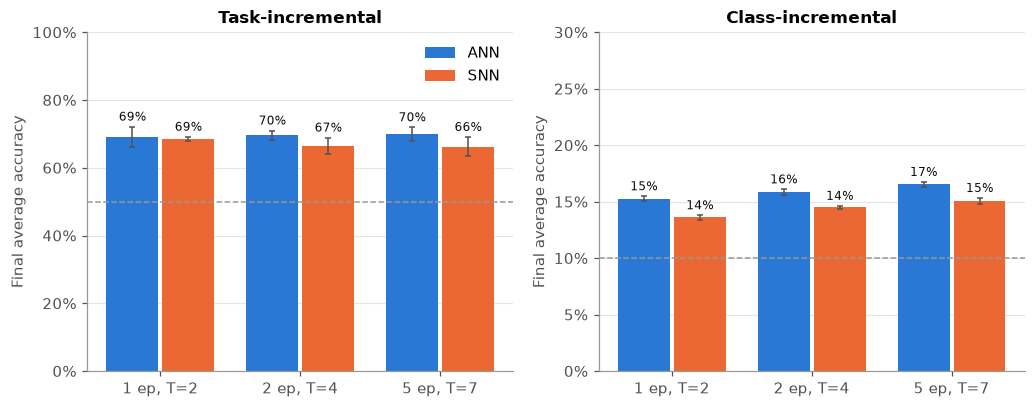

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (sc, conds) in zip(axes, data.items()):
    series = [tuple(np.array([final_acc(c[m]["runs"]) for c in conds]).T) for m in ("ann", "snn")]
    grouped_bars(ax, [cond_label(c) for c in conds], series,
                 [MODEL_COLORS["ann"], MODEL_COLORS["snn"]], ["ANN", "SNN"])
    ax.axhline(CHANCE[sc], ls="--", lw=1, color="#9a998f")
    ax.set_title(SCENARIO_TITLE[sc])
    ax.set_ylabel("Final average accuracy")
    ax.set_ylim(0, 1 if sc == "task" else 0.3)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].legend(loc="upper right")
fig.savefig(FIG_DIR / "baseline_final_accuracy.png")
plt.show()

## 2. Accuracy as tasks are added
**What it shows:** after each task is trained (x-axis), the average accuracy over all tasks seen so far (y-axis). Top row: task-incremental. Bottom row: class-incremental. One column per condition.

**How to read it:** the point at x = 1 is just task 1. Each later point adds one more task to the average, so a falling line means old tasks are being forgotten faster than the new task adds.

**What to look for:**
- **Class-incremental:** a sharp drop at task 2 that keeps falling, roughly following 1 ÷ (number of tasks seen). That's the pattern of a model that only remembers its most recent task.
- **Task-incremental:** a gentler decline that levels off.
- **ANN vs SNN:** whether the gap between the two lines grows as more tasks are added.

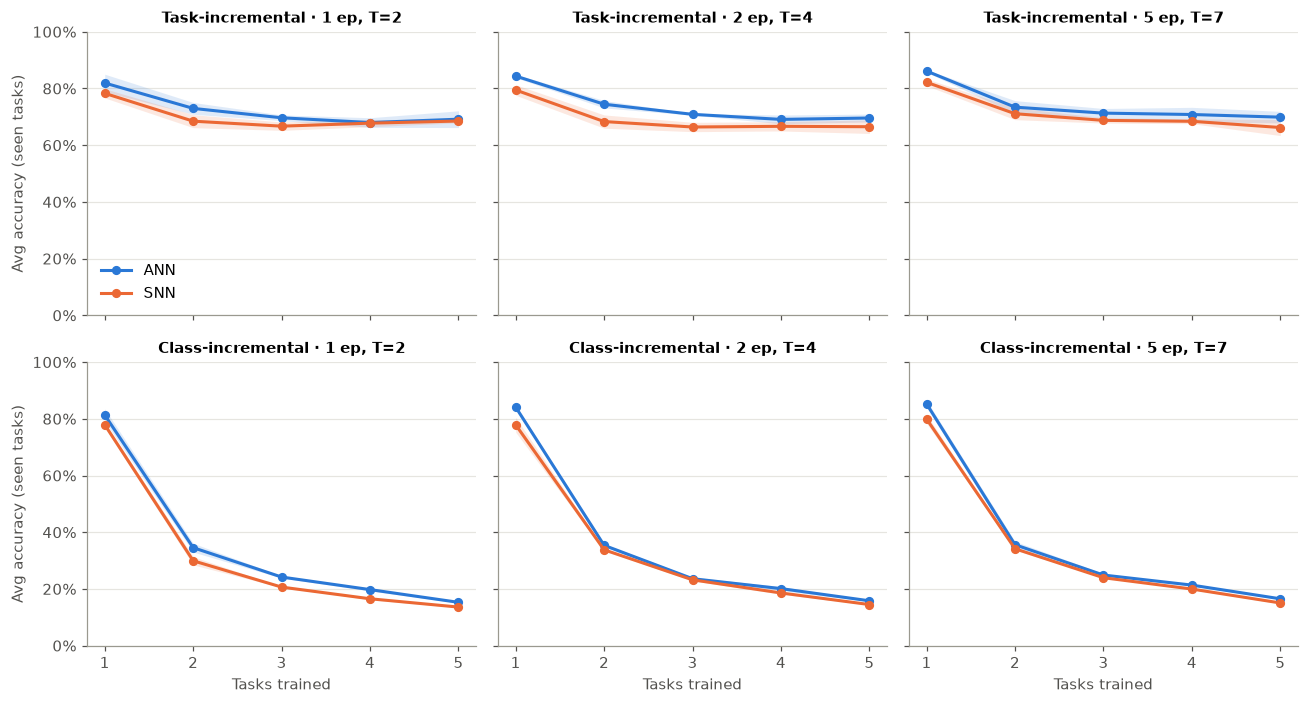

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey="row")
x = np.arange(1, 6)
for row, (sc, conds) in enumerate(data.items()):
    for col, c in enumerate(conds):
        ax = axes[row, col]
        for m in ("ann", "snn"):
            cv = curve(c[m]["runs"])
            mu, sd = cv.mean(0), cv.std(0)
            ax.plot(x, mu, "-o", lw=2, ms=5, color=MODEL_COLORS[m], label=MODEL_NAMES[m])
            ax.fill_between(x, mu - sd, mu + sd, color=MODEL_COLORS[m], alpha=0.15, lw=0)
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {cond_label(c)}", fontsize=10)
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if col == 0:
            ax.set_ylabel("Avg accuracy (seen tasks)")
        if row == 1:
            ax.set_xlabel("Tasks trained")
axes[0, 0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_accuracy_curves.png")
plt.show()

## 3. Accuracy matrix
**What it shows:** the full history of every task's accuracy throughout training (condition 3: 5 epochs, T = 7; mean over seeds).

**How to read it:**
- Each **row** is a moment in training: just after training task 1, 2, …, 5.
- Each **column** is one task's test accuracy.
- The **diagonal** is how well each task was learned when it was the current task.
- **Reading down a column** follows one task over time. Paler cells further down mean that task is being forgotten.
- The upper-right triangle is empty because those tasks haven't been trained yet.

**What to look for:**
- **Class-incremental:** everything left of the diagonal drops to 0% straight away. Each new task completely overwrites the old ones.
- **Task-incremental:** old tasks fade gradually rather than vanishing.
- **ANN vs SNN:** whether one network keeps old tasks for longer.

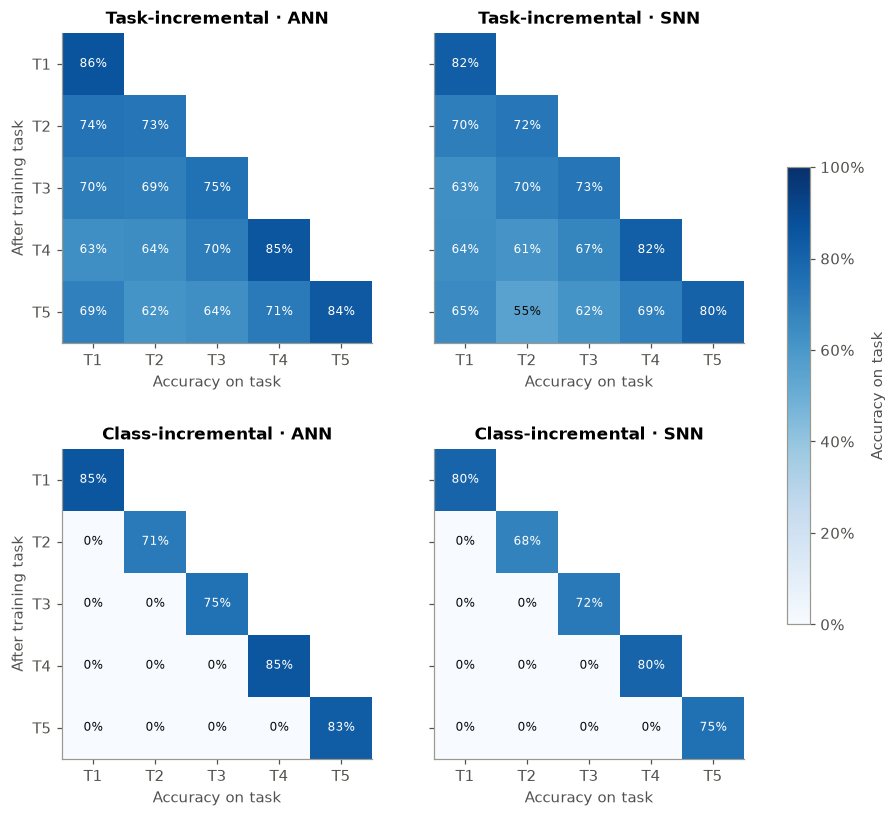

In [5]:
COND = -1  # last condition (5 epochs, T=7)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for row, (sc, conds) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        M = acc_matrix(conds[COND][m]["runs"])
        im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
        for i in range(5):
            for j in range(i + 1):
                ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if M[i, j] > 0.6 else "#0b0b0b")
        ax.set_xticks(range(5), [f"T{j+1}" for j in range(5)])
        ax.set_yticks(range(5), [f"T{i+1}" for i in range(5)] if col == 0 else [])
        if col == 0:
            ax.set_ylabel("After training task")
        ax.set_xlabel("Accuracy on task")
        ax.grid(False)
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
fig.colorbar(im, ax=axes, shrink=0.6, label="Accuracy on task",
             format=plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
fig.savefig(FIG_DIR / "baseline_accuracy_matrix.png")
plt.show()

## 4. Forgetting
**What it shows:** how much accuracy tasks 1–4 lost by the end of training, averaged over the four tasks. Task 5 is left out because nothing is trained after it.

**How to read it:** **lower is better.** A score of 0% means nothing was forgotten. A score equal to the task's original accuracy means it was forgotten completely.

**What to look for:**
- **Class-incremental:** forgetting close to the original accuracy, i.e. near-total loss.
- **Task-incremental:** much smaller forgetting.
- **Effect of conditions:** whether more epochs per task (condition 3) increases forgetting. Training longer on each new task moves the shared weights further from what earlier tasks needed.

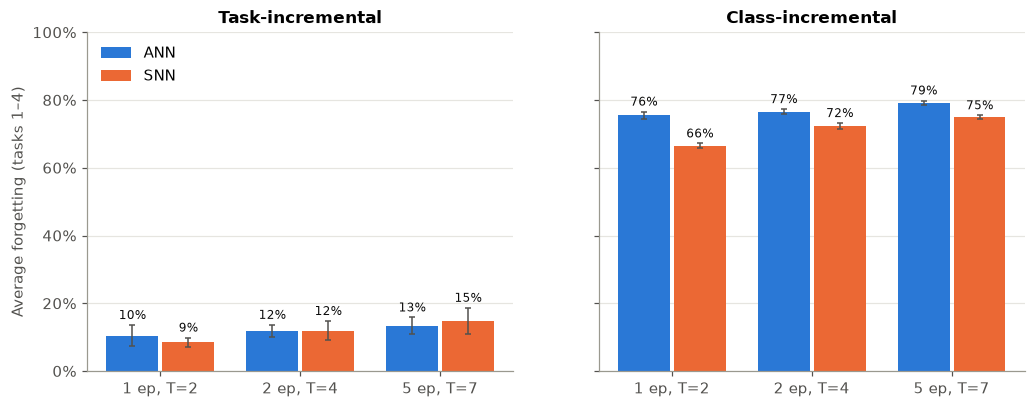

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (sc, conds) in zip(axes, data.items()):
    series = [tuple(np.array([forgetting(c[m]["runs"]) for c in conds]).T) for m in ("ann", "snn")]
    grouped_bars(ax, [cond_label(c) for c in conds], series,
                 [MODEL_COLORS["ann"], MODEL_COLORS["snn"]], ["ANN", "SNN"])
    ax.set_title(SCENARIO_TITLE[sc])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Average forgetting (tasks 1–4)")
axes[0].legend(loc="upper left")
fig.savefig(FIG_DIR / "baseline_forgetting.png")
plt.show()

## 5. Final accuracy per task
**What it shows:** each task's accuracy at the very end of training (condition 3), i.e. the bottom row of the accuracy matrix shown as bars.

**How to read it:** bars on the right (recent tasks) should be higher than bars on the left (old tasks). Bars that are missing are at 0%.

**What to look for:**
- **Class-incremental:** only task 5 survives.
- **Task-incremental:** which tasks are hardest to keep. Visually similar pairs such as bird/cat (T2) and deer/dog (T3) are also the hardest to learn in the first place.

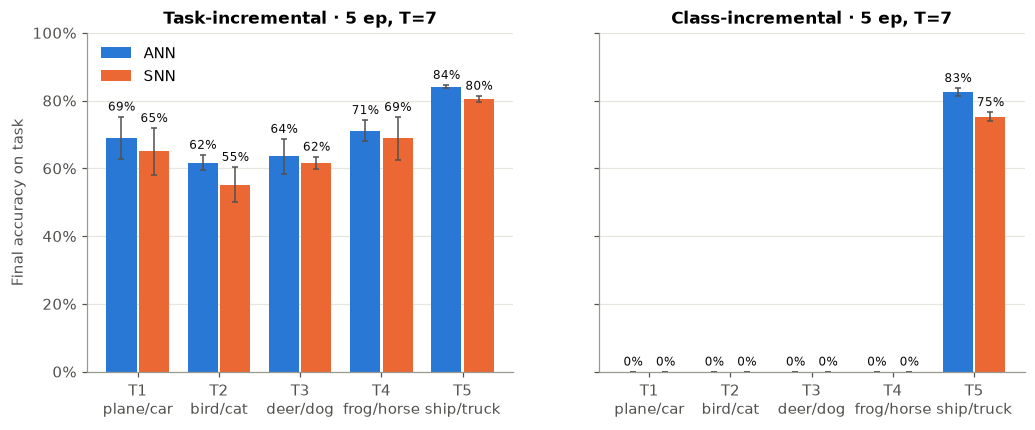

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (sc, conds) in zip(axes, data.items()):
    series = []
    for m in ("ann", "snn"):
        accs = np.array([r["tasks"][-1]["task_accuracies"] for r in conds[COND][m]["runs"]])
        series.append((accs.mean(0), accs.std(0)))
    grouped_bars(ax, [n.replace(" ", "\n", 1) for n in TASK_NAMES], series,
                 [MODEL_COLORS["ann"], MODEL_COLORS["snn"]], ["ANN", "SNN"])
    ax.set_title(f"{SCENARIO_TITLE[sc]} · {cond_label(conds[COND])}")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Final accuracy on task")
axes[0].legend(loc="upper left")
fig.savefig(FIG_DIR / "baseline_per_task_accuracy.png")
plt.show()

## 6. Training time
**What it shows:** total time to train all 5 tasks for one seed, in minutes.

**How to read it:** the SNN repeats the forward pass once per time step, so its cost grows with both epochs and T. The ANN's cost grows only with epochs. Times are only comparable for runs made on the same machine.

**What to look for:** how many times slower the SNN is than the ANN, and whether that ratio grows with T. That's the computational cost of using a spiking network, to set against any accuracy or forgetting benefit.

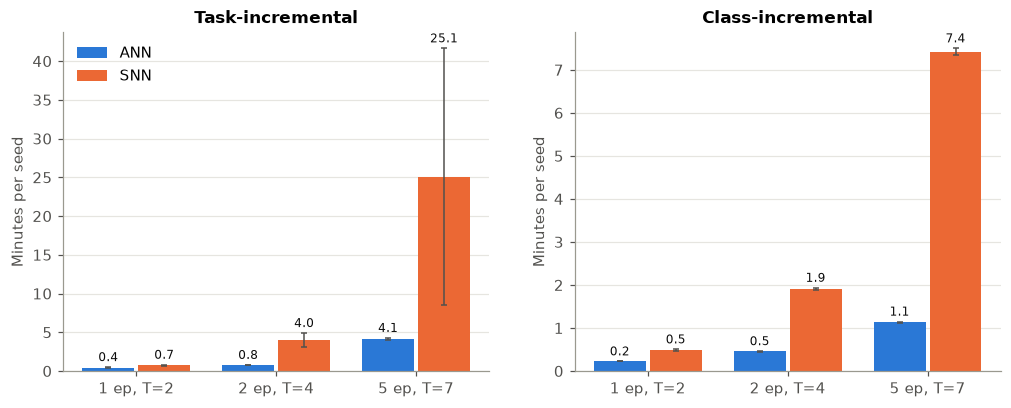

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (sc, conds) in zip(axes, data.items()):
    series = [tuple(np.array([train_time(c[m]["runs"]) for c in conds]).T) for m in ("ann", "snn")]
    grouped_bars(ax, [cond_label(c) for c in conds], series,
                 [MODEL_COLORS["ann"], MODEL_COLORS["snn"]], ["ANN", "SNN"], fmt="{:.1f}")
    ax.set_title(SCENARIO_TITLE[sc])
    ax.set_ylabel("Minutes per seed")
axes[0].legend(loc="upper left")
fig.savefig(FIG_DIR / "baseline_training_time.png")
plt.show()